### original dataset

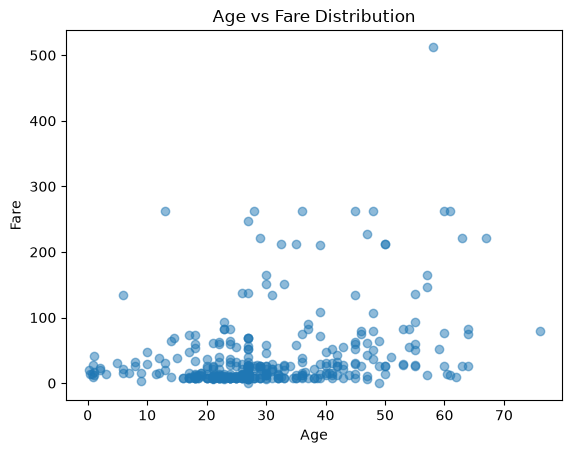

In [17]:
import matplotlib.pyplot as plt
import pandas as pd
df = pd.read_csv("cleaned_titanic.csv")
plt.scatter(df["Age"], df["Fare"], alpha=0.5)

plt.xlabel("Age")
plt.ylabel("Fare")
plt.title("Age vs Fare Distribution")

plt.show()

Training data: (334, 1)
Testing data: (84, 1)

Predicted values:
[29.88015288 51.8113622  23.61409308 45.54530239 47.11181735 69.04302666
 36.14621269 67.47651171 20.48106317 33.01318278 23.61409308 70.60954161
 15.78151832 51.8113622  33.01318278 33.01318278 34.57969774 76.87560142
  6.38242861 26.74712298 80.00863132 54.9443921  -4.58317605 37.71272764
 33.01318278 19.6978057  29.88015288 33.01318278 51.8113622  37.71272764
 40.84575754 25.18060803 42.41227249 33.01318278 25.18060803 29.88015288
 28.31363793 33.01318278 36.14621269 41.62901502 28.31363793 33.01318278
 54.9443921  33.01318278 35.36295521 23.61409308 33.01318278 28.31363793
 76.87560142 47.11181735 44.76204492 61.21045191 33.01318278 64.34348181
 36.14621269 22.04757812 33.01318278 31.44666783 -9.01641336 28.31363793
 69.04302666 23.61409308 33.01318278 53.37787715 14.21500337 29.88015288
 54.9443921  28.31363793 51.8113622  58.077422   80.00863132 37.71272764
 40.84575754 33.01318278 61.21045191 25.18060803 37.7127276

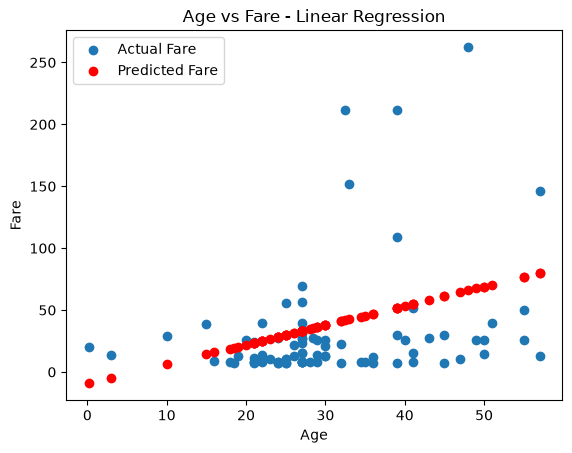

In [14]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn import linear_model
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn import metrics


df = pd.read_csv("cleaned_titanic.csv")


X = df[["Age"]]
y = df["Fare"]


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)


reg = linear_model.LinearRegression()


reg.fit(X_train, y_train)


y_pred = reg.predict(X_test)

print("\nPredicted values:")
print(y_pred)


print("\nModel Evaluation")

print("Mean Squared Error:",
      metrics.mean_squared_error(y_test, y_pred))

print("Root Mean Squared Error:",
      np.sqrt(metrics.mean_squared_error(y_test, y_pred)))

print("R2 Score:",
      metrics.r2_score(y_test, y_pred))

print("\nCoefficient:", reg.coef_)
print("Intercept:", reg.intercept_)

res = reg.predict(pd.DataFrame({"Age": [30]}))

print("\nPredicted Fare for Age 30:", res[0])


result = X_test.copy()
result["Actual_Fare"] = y_test
result["Predicted_Fare"] = y_pred

result.to_csv("titanic_predictions.csv", index=False)

print("\nPredictions saved successfully!")


plt.scatter(X_test["Age"], y_test, label="Actual Fare")

plt.scatter(X_test["Age"], y_pred,
            color="red", label="Predicted Fare")

plt.xlabel("Age")
plt.ylabel("Fare")
plt.title("Age vs Fare - Linear Regression")
plt.legend()
plt.show()


### Scatter Plot

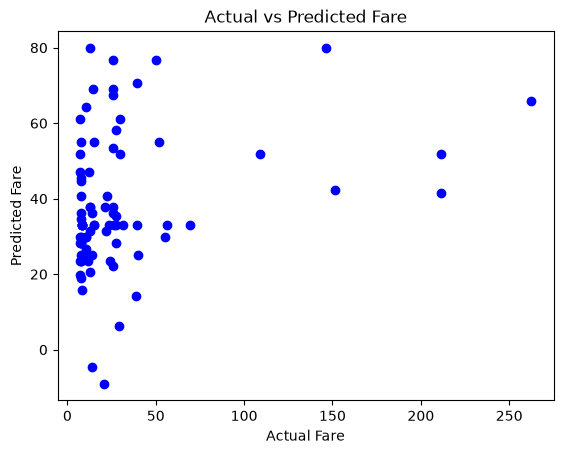

In [5]:
plt.scatter(y_test, y_pred, color="blue")

plt.xlabel("Actual Fare")
plt.ylabel("Predicted Fare")
plt.title("Actual vs Predicted Fare")

plt.show()

### Line Chart

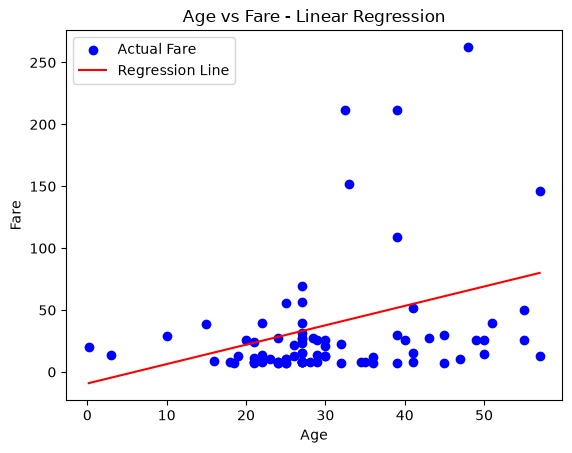

In [ ]:
plt.scatter(X_test["Age"], y_test, color="blue", label="Actual Fare")

sorted_indices = X_test["Age"].values.argsort()

plt.plot(
    X_test["Age"].values[sorted_indices],
    y_pred[sorted_indices],
    color="red",
    label="Regression Line"
)

plt.xlabel("Age")
plt.ylabel("Fare")
plt.title("Age vs Fare - Linear Regression")
plt.legend()
plt.show()

### Histogram

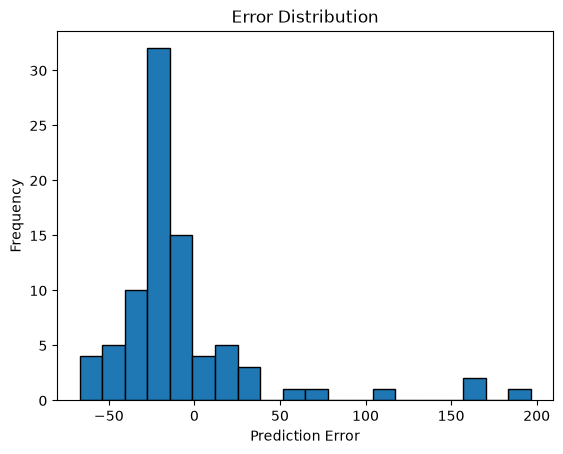

In [7]:
errors = y_test - y_pred

plt.hist(errors, bins=20, edgecolor="black")

plt.xlabel("Prediction Error")
plt.ylabel("Frequency")
plt.title("Error Distribution")

plt.show()

### Bar Chart

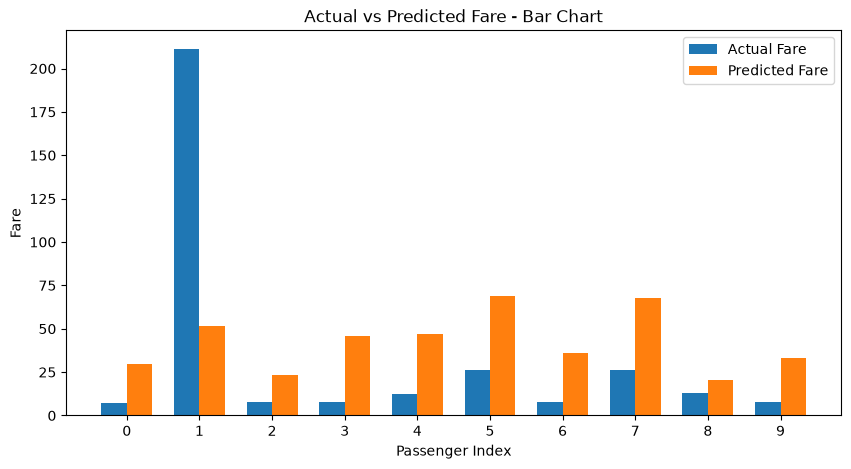

In [ ]:
plt.figure(figsize=(10, 5))


actual = y_test.values[:10]
predicted = y_pred[:10]

x = np.arange(10)
width = 0.35

plt.bar(x - width/2, actual, width, label="Actual Fare")
plt.bar(x + width/2, predicted, width, label="Predicted Fare")

plt.xlabel("Passenger Index")
plt.ylabel("Fare")
plt.title("Actual vs Predicted Fare - Bar Chart")

plt.xticks(x)
plt.legend()
plt.show()